Dataset preparado:
  Treino inicial: 100 exemplos
  Pool: 1247 exemplos
  Teste: 450 exemplos

Acurácia inicial: 0.8333

Vais rotular 20 dígitos.
Observa bem cada imagem e insere o número correspondente (0-9).


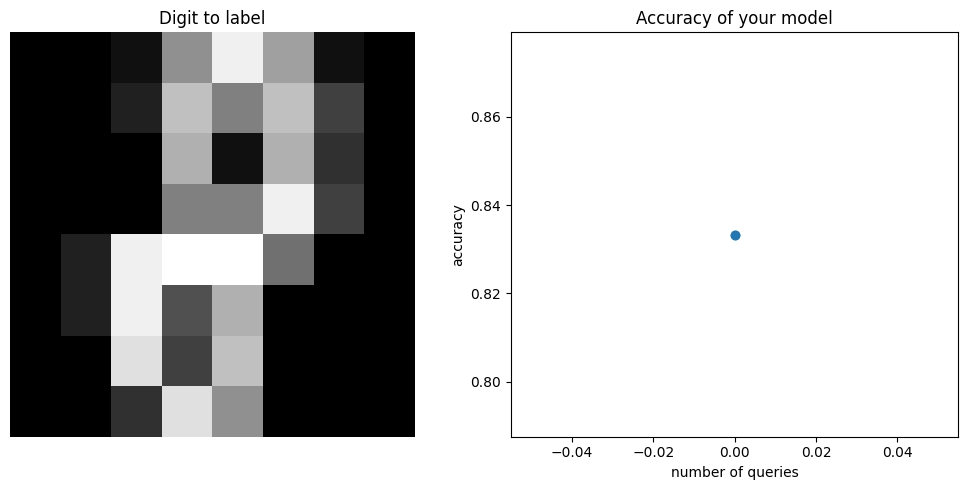


Query 1/20
Which digit is this?
❌ Era 8 (disseste 6)
Acurácia: 0.8267


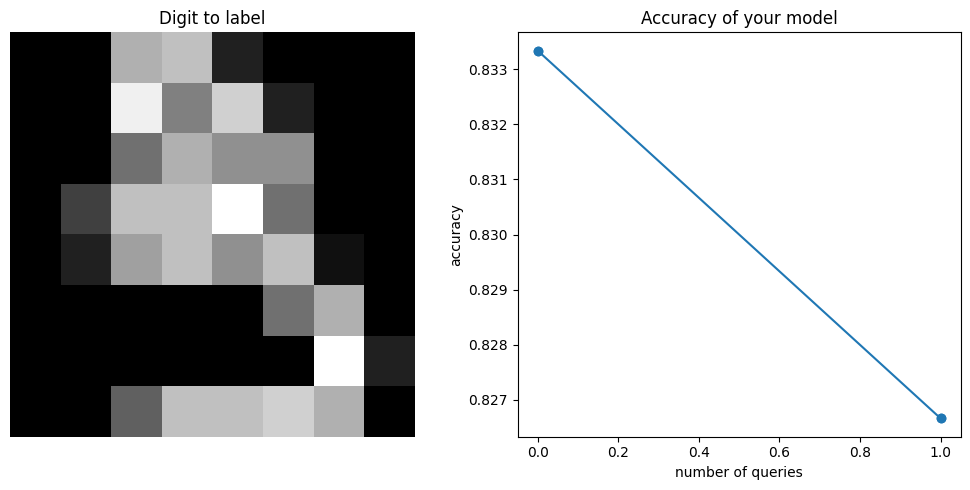


Query 2/20
Which digit is this?
✅ Correto!
Acurácia: 0.8111


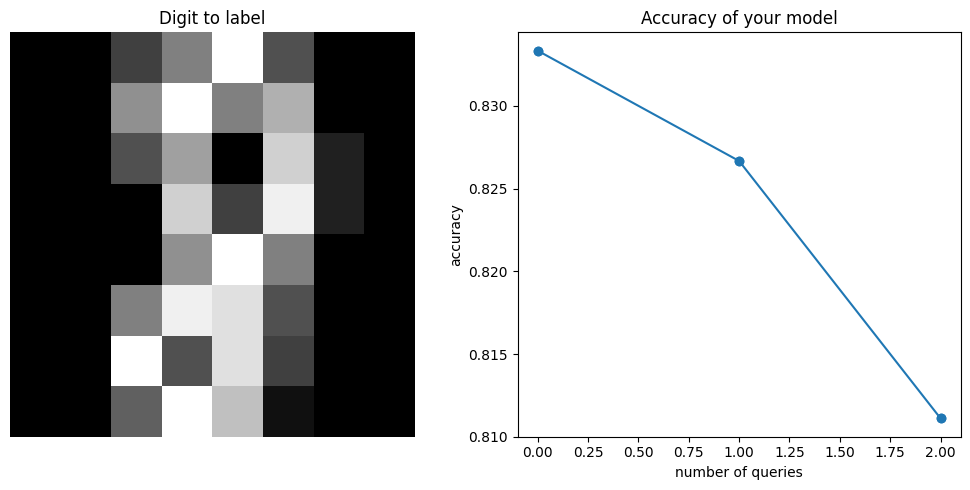


Query 3/20
Which digit is this?
❌ Era 8 (disseste 3)
Acurácia: 0.7978


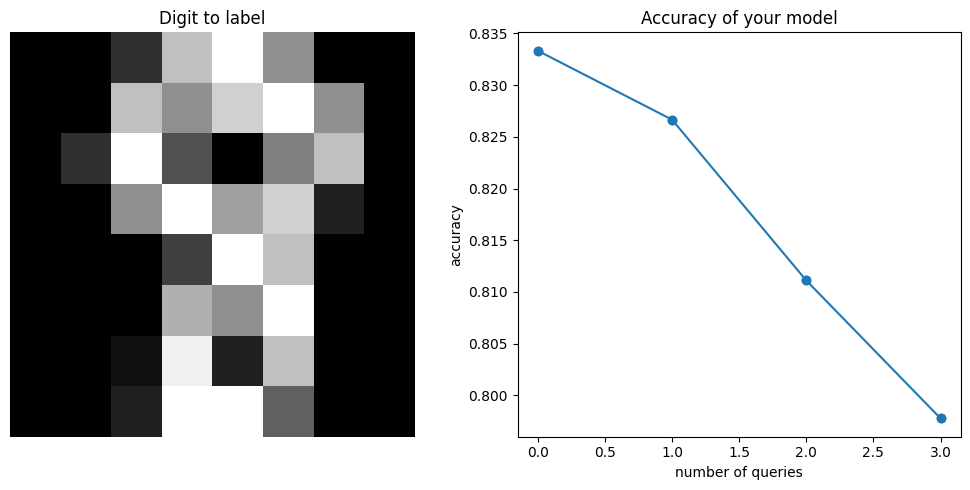


Query 4/20
Which digit is this?
✅ Correto!
Acurácia: 0.7956


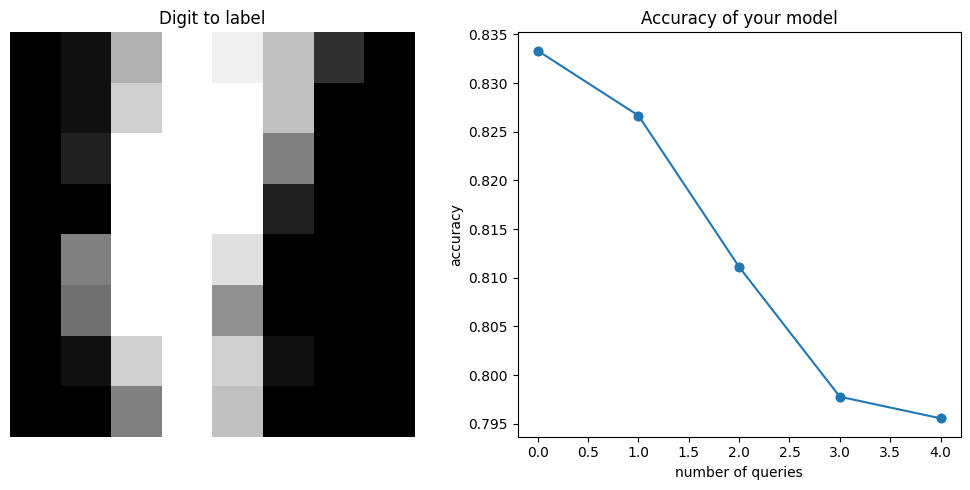


Query 5/20
Which digit is this?
❌ Era 1 (disseste 7)
Acurácia: 0.7933


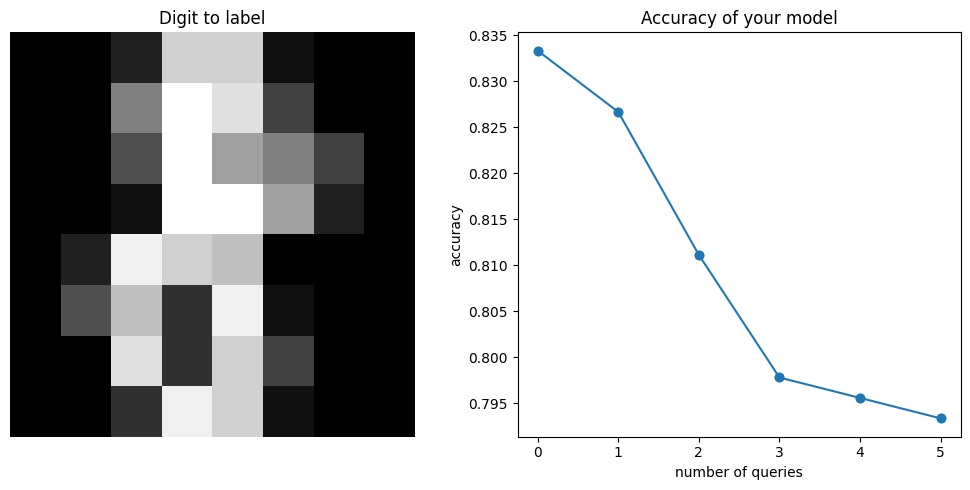


Query 6/20
Which digit is this?
❌ Era 8 (disseste 6)
Acurácia: 0.7933


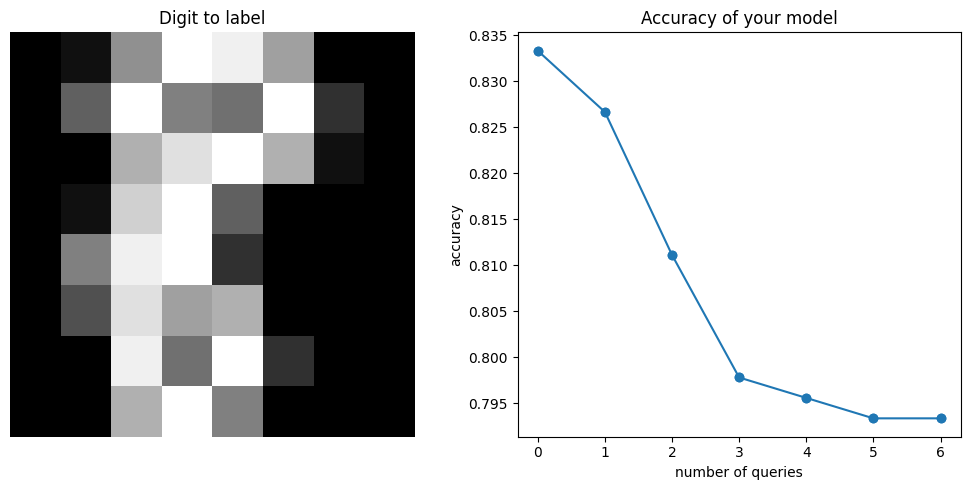


Query 7/20
Which digit is this?
❌ Era 8 (disseste 5)
Acurácia: 0.7756


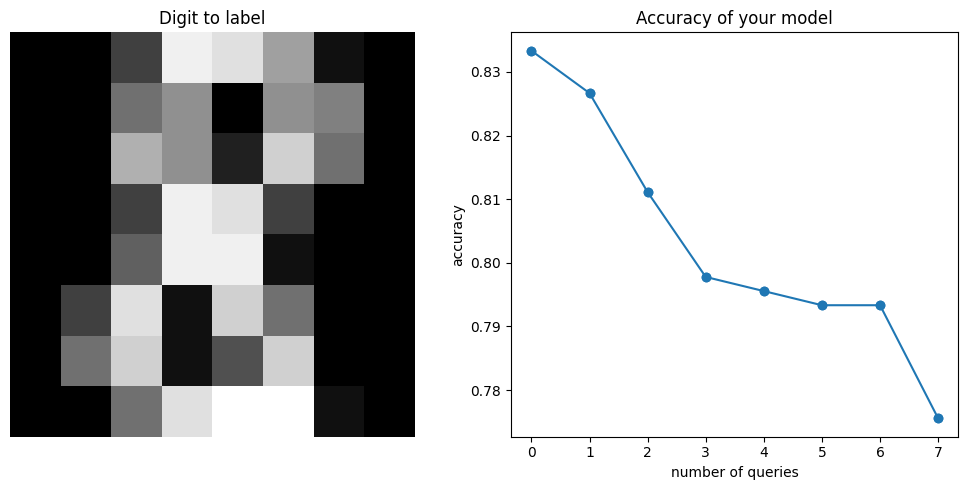


Query 8/20
Which digit is this?
❌ Era 8 (disseste 2)
Acurácia: 0.7978


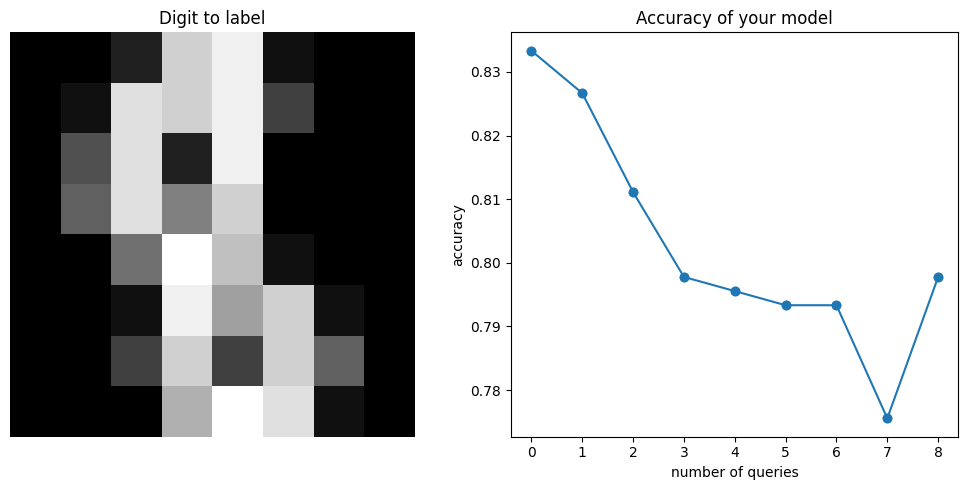


Query 9/20
Which digit is this?
✅ Correto!
Acurácia: 0.7978


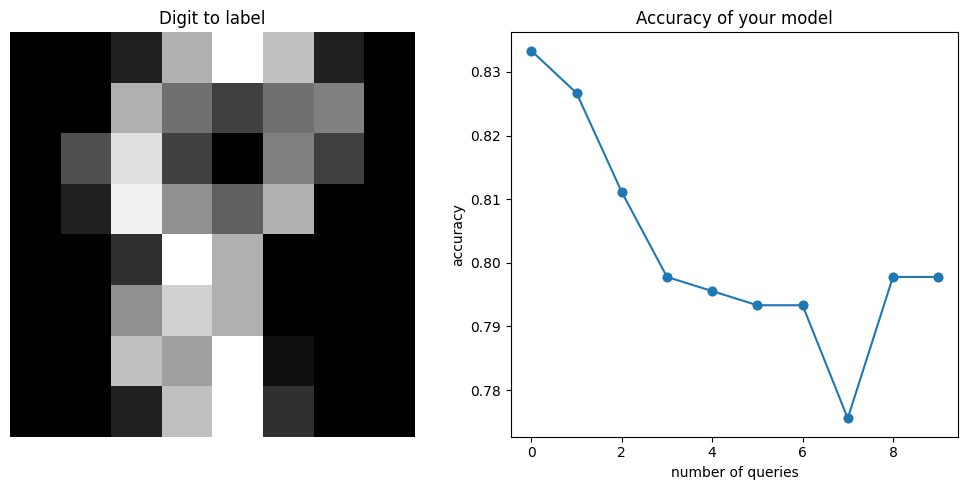


Query 10/20
Which digit is this?
❌ Era 8 (disseste 9)
Acurácia: 0.7800


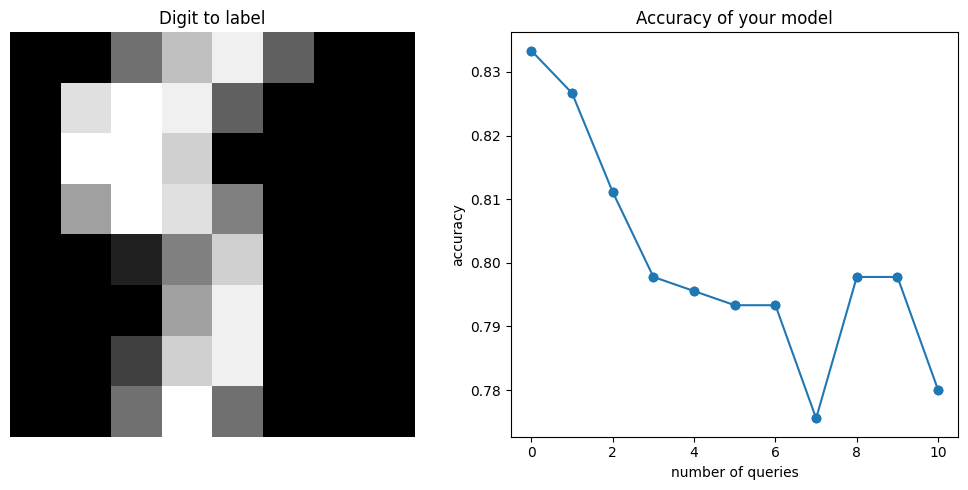


Query 11/20
Which digit is this?
❌ Era 5 (disseste 1)
Acurácia: 0.7956


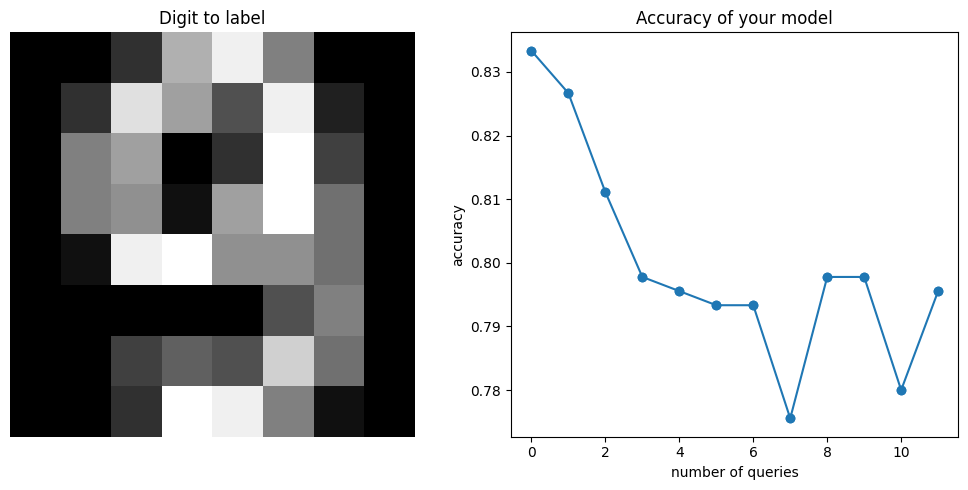


Query 12/20
Which digit is this?
✅ Correto!
Acurácia: 0.8022


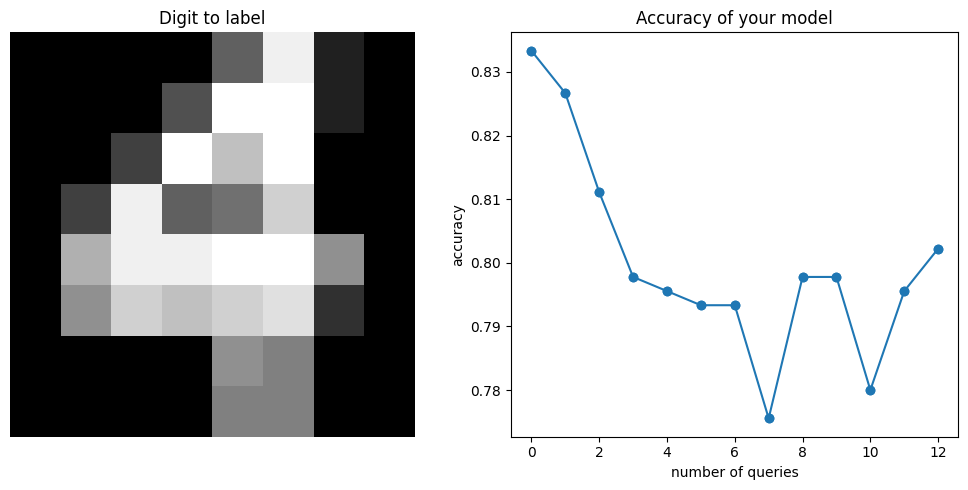


Query 13/20
Which digit is this?
✅ Correto!
Acurácia: 0.7933


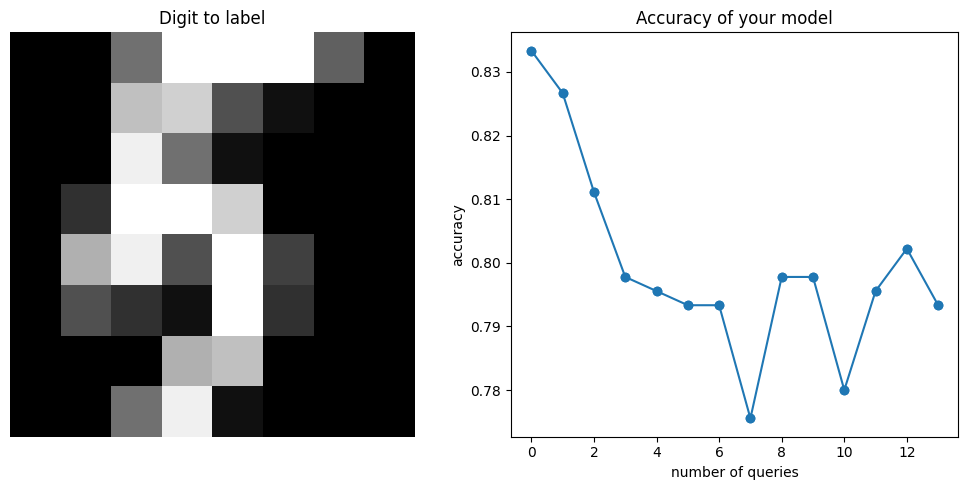


Query 14/20
Which digit is this?
❌ Era 5 (disseste 6)
Acurácia: 0.8067


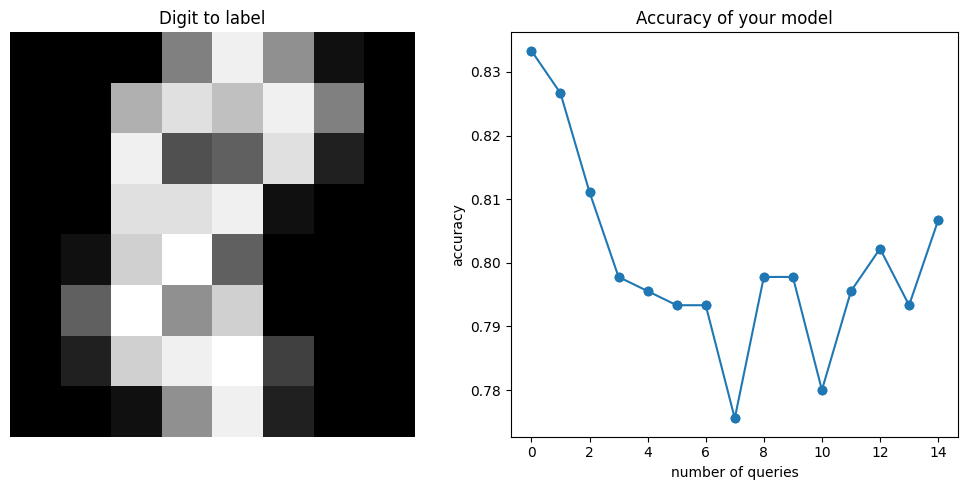


Query 15/20
Which digit is this?
❌ Era 8 (disseste 5)
Acurácia: 0.8156


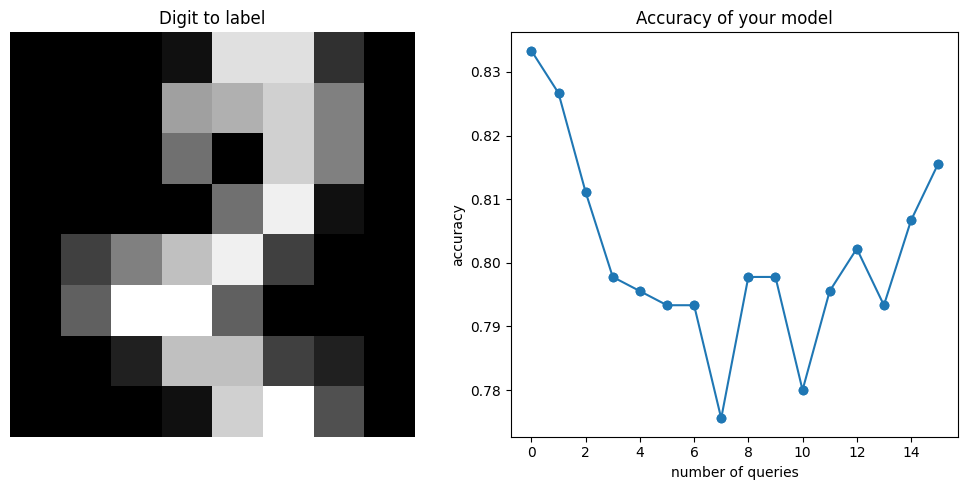


Query 16/20
Which digit is this?
✅ Correto!
Acurácia: 0.7911


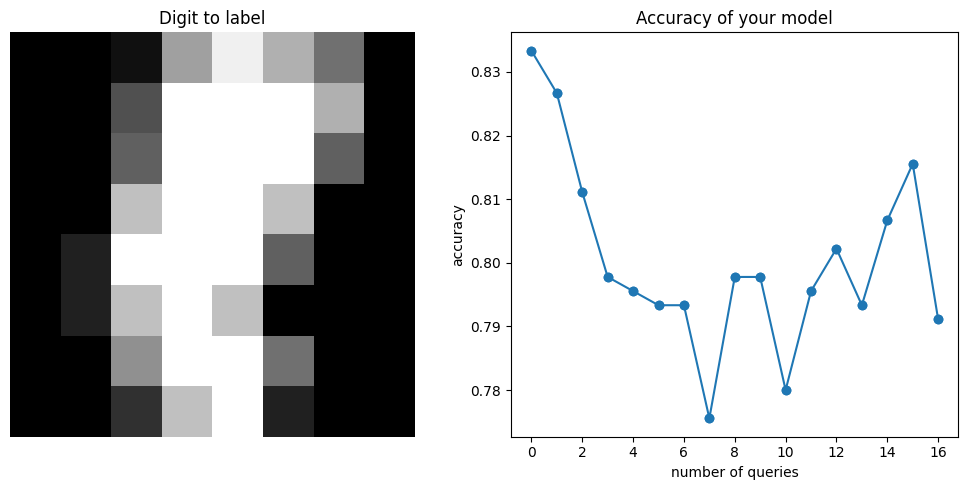


Query 17/20
Which digit is this?


In [ ]:
"""
Interactive Labeling com Active Learning - SEM modAL
====================================================
Implementação que segue EXATAMENTE o código original do notebook.

Autor: Adaptado de interactive_labeling.ipynb
Data: 16 de Outubro de 2025
"""

import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score
import warnings

warnings.filterwarnings("ignore")

# Configurar matplotlib para modo interativo
plt.ion()  # Ativar modo interativo

# =============================================================================
# FUNÇÕES DE ACTIVE LEARNING (substitui modAL)
# =============================================================================

def uncertainty_sampling(model, X_pool):
    """
    Seleciona o exemplo mais incerto do pool
    Retorna: (query_idx, query_inst) igual ao modAL
    """
    proba = model.predict_proba(X_pool)
    uncertainty = 1 - np.max(proba, axis=1)
    query_idx = np.argmax(uncertainty)
    query_inst = X_pool[query_idx].reshape(1, -1)
    return query_idx, query_inst


class ActiveLearner:
    """
    Substitui modAL.models.ActiveLearner
    Interface idêntica ao original
    """

    def __init__(self, estimator, query_strategy, X_training, y_training):
        """
        Parâmetros:
        -----------
        estimator: modelo (ex: RandomForestClassifier)
        query_strategy: função de estratégia (não usada, mantida por compatibilidade)
        X_training: dados de treino iniciais
        y_training: labels de treino iniciais
        """
        self.estimator = estimator
        self.X_training = X_training.copy()
        self.y_training = y_training.copy()
        self.estimator.fit(self.X_training, self.y_training)

    def query(self, X_pool):
        """
        Seleciona o exemplo mais informativo
        Retorna: (query_idx, query_inst)
        """
        return uncertainty_sampling(self.estimator, X_pool)

    def teach(self, X_new, y_new):
        """
        Adiciona novos exemplos e re-treina
        """
        self.X_training = np.vstack([self.X_training, X_new])
        self.y_training = np.concatenate([self.y_training, y_new])
        self.estimator.fit(self.X_training, self.y_training)

    def score(self, X_test, y_test):
        """
        Calcula acurácia
        """
        return accuracy_score(y_test, self.estimator.predict(X_test))


# =============================================================================
# CÓDIGO ORIGINAL DO NOTEBOOK (adaptado sem modAL)
# =============================================================================

# Número de exemplos iniciais
n_initial = 100

# Carregar e preparar dados
X, y = load_digits(return_X_y=True)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)

initial_idx = np.random.choice(range(len(X_train)), size=n_initial, replace=False)

X_initial, y_initial = X_train[initial_idx], y_train[initial_idx]
X_pool, y_pool = np.delete(X_train, initial_idx, axis=0), np.delete(y_train, initial_idx, axis=0)

print("Dataset preparado:")
print(f"  Treino inicial: {len(X_initial)} exemplos")
print(f"  Pool: {len(X_pool)} exemplos")
print(f"  Teste: {len(X_test)} exemplos")

# Criar learner (substitui modAL.models.ActiveLearner)
learner = ActiveLearner(
    estimator=RandomForestClassifier(n_estimators=50, random_state=42),
    query_strategy=uncertainty_sampling,  # Mantido por compatibilidade
    X_training=X_initial,
    y_training=y_initial
)

print(f"\nAcurácia inicial: {learner.score(X_test, y_test):.4f}")

# Número de queries
n_queries = 20

print(f"\nVais rotular {n_queries} dígitos.")
print("Observa bem cada imagem e insere o número correspondente (0-9).")
input("\nPressiona ENTER para começar...")

# =============================================================================
# LOOP INTERATIVO - CÓDIGO ORIGINAL DO NOTEBOOK
# =============================================================================

accuracy_scores = [learner.score(X_test, y_test)]

for i in range(n_queries):
    query_idx, query_inst = learner.query(X_pool)

    # Fechar figuras anteriores
    plt.close('all')

    # Visualização (igual ao notebook original)
    fig = plt.figure(figsize=(10, 5))

    # Subplot 1: Dígito
    plt.subplot(1, 2, 1)
    plt.title('Digit to label')
    plt.imshow(query_inst.reshape(8, 8), cmap='gray')
    plt.axis('off')

    # Subplot 2: Acurácia
    plt.subplot(1, 2, 2)
    plt.title('Accuracy of your model')
    plt.plot(range(i+1), accuracy_scores, marker='o')
    plt.scatter(range(i+1), accuracy_scores)
    plt.xlabel('number of queries')
    plt.ylabel('accuracy')

    plt.tight_layout()
    plt.draw()
    plt.pause(0.1)  # Dar tempo para o gráfico aparecer
    plt.show(block=False)  # Mostrar sem bloquear

    # Input do utilizador (EXATAMENTE como no original)
    print(f"\n{'='*60}")
    print(f"Query {i+1}/{n_queries}")
    print('='*60)
    print("Which digit is this?")

    try:
        y_new = np.array([int(input(">>> "))], dtype=int)
    except ValueError:
        print("Input inválido! A usar label correto...")
        y_new = np.array([y_pool[query_idx]], dtype=int)

    # Mostrar se acertou
    correct_label = y_pool[query_idx]
    if y_new[0] == correct_label:
        print(f"✅ Correto!")
    else:
        print(f"❌ Era {correct_label} (disseste {y_new[0]})")

    learner.teach(query_inst.reshape(1, -1), y_new)
    X_pool, y_pool = np.delete(X_pool, query_idx, axis=0), np.delete(y_pool, query_idx, axis=0)
    accuracy_scores.append(learner.score(X_test, y_test))

    print(f"Acurácia: {accuracy_scores[-1]:.4f}")

# Fechar gráficos do loop
plt.close('all')

# =============================================================================
# RESULTADOS FINAIS
# =============================================================================

# Desativar modo interativo para o gráfico final
plt.ioff()

# Gráfico final (igual ao notebook original)
plt.figure(figsize=(10, 5))
plt.title('Accuracy of the classifier during the active learning')
plt.plot(range(n_queries+1), accuracy_scores, marker='o', linewidth=2)
plt.scatter(range(n_queries+1), accuracy_scores, s=100)
plt.xlabel('number of queries')
plt.ylabel('accuracy')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('interactive_labeling_results.png', dpi=300, bbox_inches='tight')
plt.show()  # Agora bloqueia até fechar

print("\n" + "="*70)
print("RESULTADOS FINAIS")
print("="*70)
print(f"Acurácia inicial: {accuracy_scores[0]:.4f}")
print(f"Acurácia final:   {accuracy_scores[-1]:.4f}")
improvement = accuracy_scores[-1] - accuracy_scores[0]
print(f"Melhoria:         {improvement:+.4f} ({(improvement/accuracy_scores[0]*100):+.2f}%)")
print(f"\n✓ Gráfico salvo como 'interactive_labeling_results.png'")
